# Breast Cancer Detection - Analysis Notebook
End-to-end walkthrough on the Wisconsin Diagnostic Breast Cancer (WDBC) dataset:
exploration, cleaning, leak-free modelling, model comparison, threshold selection and
final test evaluation.

**Positive class = Malignant (1).** In screening, a *missed* cancer (false negative) is
far more costly than a false alarm, so recall on the malignant class drives the decisions.

The heavy training (GridSearchCV) lives in `src/train.py`; this notebook explores the data,
demonstrates the leakage safeguards and *loads the real results* produced by that script.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, preprocessing, evaluate

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
VIZ = config.VIZ_DIR; VIZ.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: C:\Users\zaira\breast-cancer-detection\breast-cancer-detection


## 1. Load and explore

In [2]:
raw = preprocessing.load_data()
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

The file has 33 columns: an `id`, the `diagnosis` label, 30 numeric features and an
`Unnamed: 32` column that is completely empty (a trailing comma in the CSV).

## 2. Cleaning: missing values and duplicates

In [4]:
print("Missing values per column (non-zero only):")
print(raw.isna().sum()[raw.isna().sum() > 0])
print("\nDuplicate rows:", raw.duplicated().sum())
print("Duplicate patient ids:", raw["id"].duplicated().sum())

X, y, report = preprocessing.clean_data(raw)
print("\nCleaning report:", report)

Missing values per column (non-zero only):
Series([], dtype: int64)

Duplicate rows: 0
Duplicate patient ids: 0

Cleaning report: {'raw_shape': [569, 32], 'dropped_columns': ['id'], 'missing_values': 0, 'duplicate_rows': 0, 'clean_shape': [569, 30], 'class_counts': {'Benign': 357, 'Malignant': 212}, 'class_percentages': {'Benign': 62.741652021089635, 'Malignant': 37.258347978910365}, 'target_excluded_from_features': True}


The only missing values come from the empty `Unnamed: 32` column, which is dropped along
with `id` (an identifier carries no biological signal and could leak row identity).
After cleaning there are no missing values and no duplicates, so no imputation is needed.

## 3. Class distribution

In [5]:
counts = y.map(config.CLASS_NAMES).value_counts()
fig, ax = plt.subplots(figsize=(4.8, 3.8))
bars = ax.bar(counts.index, counts.values, color=[evaluate.BENIGN_COLOR, evaluate.MALIGNANT_COLOR])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 4, f"{v} ({v / len(y):.1%})", ha="center")
ax.set_ylabel("Cases"); ax.set_title("Class distribution")
fig.savefig(VIZ / "class_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

The data is moderately imbalanced (about 63 % benign / 37 % malignant). That is why we
use **stratified** splits and judge models on recall / precision / ROC-AUC instead of accuracy alone.

## 4. Feature distributions

In [6]:
df = X.copy(); df["Diagnosis"] = y.map(config.CLASS_NAMES)
palette = {"Benign": evaluate.BENIGN_COLOR, "Malignant": evaluate.MALIGNANT_COLOR}
mean_feats = [f for f in config.FEATURES if f.endswith("_mean")]
fig, axes = plt.subplots(2, 5, figsize=(18, 6.5))
for ax, f in zip(axes.ravel(), mean_feats):
    sns.kdeplot(data=df, x=f, hue="Diagnosis", palette=palette, fill=True, common_norm=False, ax=ax, legend=False)
    ax.set_title(config.display_name(f), fontsize=10); ax.set_xlabel("")
fig.suptitle("Distribution of the 'mean' features by diagnosis", y=1.01)
fig.tight_layout(); fig.savefig(VIZ / "feature_distributions.png", dpi=150, bbox_inches="tight"); plt.show()

Size- and shape-irregularity features (radius, perimeter, area, concavity, concave points)
separate the classes clearly; malignant nuclei are larger and more irregular. Fractal dimension
and symmetry overlap heavily (weaker individual signal).

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, f in zip(axes, ["radius_mean", "concave_points_mean", "texture_mean", "area_worst"]):
    sns.boxplot(data=df, x="Diagnosis", y=f, palette=palette, ax=ax, hue="Diagnosis", legend=False)
    ax.set_title(config.display_name(f), fontsize=10)
fig.tight_layout(); fig.savefig(VIZ / "boxplots.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Correlation analysis

In [8]:
corr = X.corr()
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, square=True,
            xticklabels=[config.display_name(c) for c in corr.columns],
            yticklabels=[config.display_name(c) for c in corr.columns],
            cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Correlation heatmap (30 features)")
fig.savefig(VIZ / "correlation_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

In [9]:
pairs = (corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
         .rename("corr").reset_index().query("abs(corr) > 0.95")
         .sort_values("corr", ascending=False))
print(f"{len(pairs)} feature pairs with |r| > 0.95. Strongest:")
print(pairs.head(8).to_string(index=False))
print("\nCorrelation of each feature with the malignant label (top 10):")
print(X.corrwith(y).sort_values(ascending=False).head(10).round(3))

15 feature pairs with |r| > 0.95. Strongest:
        level_0         level_1     corr
    radius_mean  perimeter_mean 0.997855
   radius_worst perimeter_worst 0.993708
    radius_mean       area_mean 0.987357
 perimeter_mean       area_mean 0.986507
   radius_worst      area_worst 0.984015
perimeter_worst      area_worst 0.977578
      radius_se    perimeter_se 0.972794
 perimeter_mean perimeter_worst 0.970387

Correlation of each feature with the malignant label (top 10):
concave_points_worst    0.794
perimeter_worst         0.783
concave_points_mean     0.777
radius_worst            0.776
perimeter_mean          0.743
area_worst              0.734
radius_mean             0.730
area_mean               0.709
concavity_mean          0.696
concavity_worst         0.660
dtype: float64


Radius, perimeter and area are almost perfectly collinear (r > 0.97 in the pairs above), as are their 'worst'
counterparts. We keep all 30 features (the app requires them) and rely on models that cope with
collinearity: L2-regularised Logistic Regression, an RBF-SVM and Random Forest.

## 6. Stratified split and leakage prevention
60 % train / 20 % validation / 20 % test, stratified, fixed seed.
- **Train**: fit models and run GridSearchCV.
- **Validation**: compare models and choose the decision threshold.
- **Test**: touched once, for the final model only.

In [10]:
s = preprocessing.split_data(X, y)
summary = pd.DataFrame({k: {"cases": len(s[f"y_{k}"]), "malignant": int(s[f"y_{k}"].sum()),
                            "malignant %": round(100 * s[f"y_{k}"].mean(), 1)}
                        for k in ("train", "val", "test")}).T
summary

,cases,malignant,malignant %
train,341.0,127.0,37.2
val,114.0,43.0,37.7
test,114.0,42.0,36.8


**Leakage demonstration.** The `StandardScaler` is a step *inside* the Pipeline. When the
pipeline is fitted, the scaler learns means only from the training rows; GridSearchCV refits the
whole pipeline on each training fold, so validation folds never influence scaling.

In [11]:
pipe = preprocessing.build_pipeline("Logistic Regression").fit(s["X_train"], s["y_train"])
scaler_mean = pd.Series(pipe.named_steps["scaler"].mean_, index=config.FEATURES)
check = pd.DataFrame({"scaler mean (fitted)": scaler_mean,
                      "train mean": s["X_train"].mean(),
                      "all-data mean": X.mean()}).head(5)
print(check)
assert np.allclose(scaler_mean, s["X_train"].mean()) and not np.allclose(scaler_mean, X.mean())
print("\nOK: scaler statistics equal the TRAINING means, not the full-data means.")

                 scaler mean (fitted)  train mean  all-data mean
radius_mean                 14.163419   14.163419      14.127292
texture_mean                19.428768   19.428768      19.289649
perimeter_mean              92.172581   92.172581      91.969033
area_mean                  659.691789  659.691789     654.889104
smoothness_mean              0.095654    0.095654       0.096360

OK: scaler statistics equal the TRAINING means, not the full-data means.


## 7. Models, tuning and comparison
`python -m src.train` tunes Logistic Regression, Random Forest and SVM (RBF) with
`GridSearchCV` (5-fold stratified CV on the training set, scoring F2, which weights recall twice
as much as precision), then evaluates each on the **validation** set at its own tuned threshold.
Results below are read from the files that script wrote.

To regenerate everything (about 1.5 minutes), run `python -m src.train` from the project root.

In [12]:
comp = pd.read_csv(config.REPORTS_DIR / "model_comparison.csv")
cols = ["model", "best_params", "cv_f2", "cv_roc_auc", "threshold", "val_accuracy",
        "val_precision", "val_recall", "val_f1", "val_roc_auc", "val_fn", "val_fn_at_0.5"]
comp[cols].round(3)

,model,best_params,cv_f2,cv_roc_auc,threshold,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,val_fn,val_fn_at_0.5
0,Logistic Regression,"{'C': 0.1, 'class_weight': 'balanced'}",0.962,0.993,0.23,0.886,0.768,1.0,0.869,0.995,0,2
1,Random Forest,"{'class_weight': 'balanced', 'max_depth': None...",0.934,0.985,0.08,0.825,0.683,1.0,0.811,0.990,0,2
2,SVM,"{'C': 100, 'class_weight': 'balanced', 'gamma'...",0.964,0.993,0.18,0.912,0.811,1.0,0.896,0.997,0,1


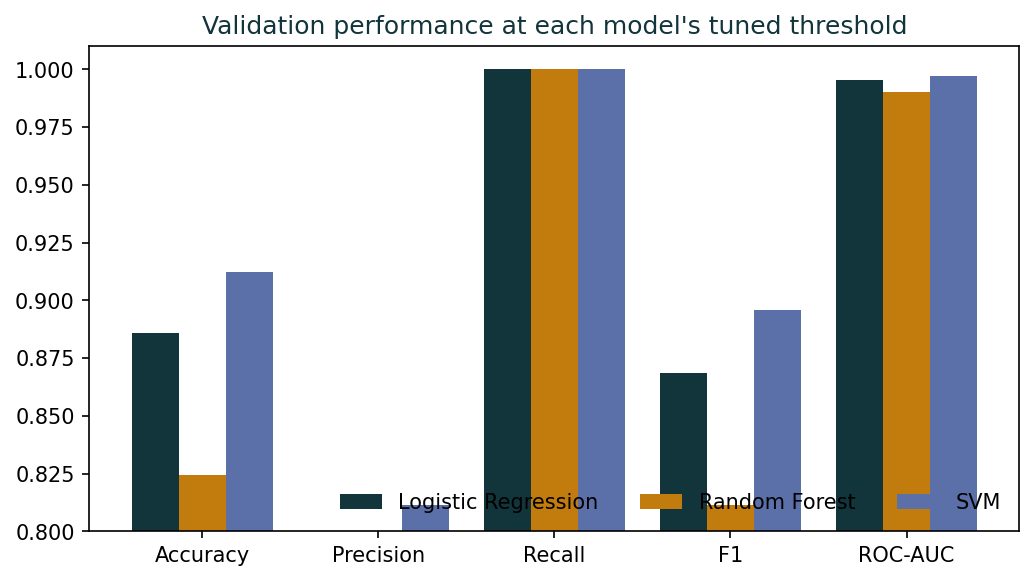

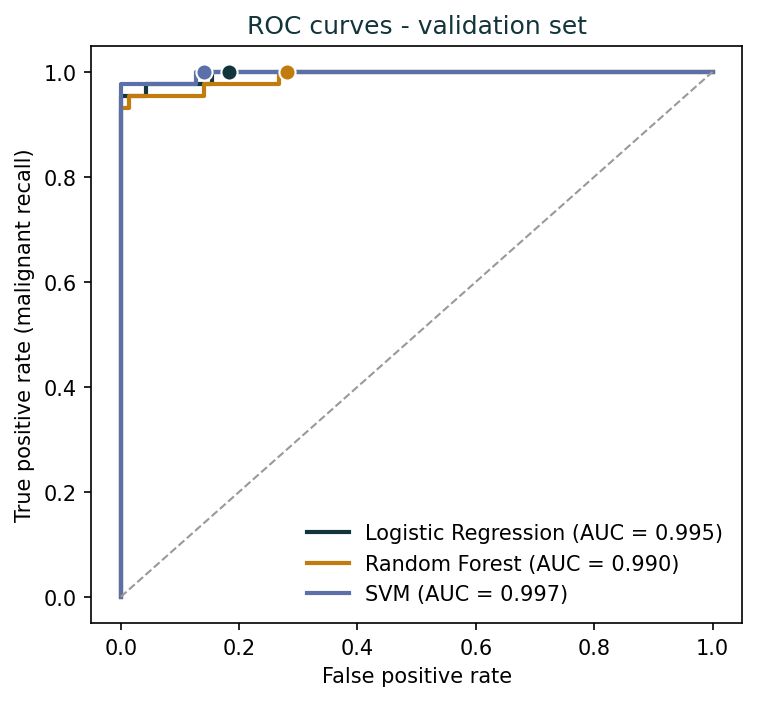

In [13]:
from IPython.display import Image, display
display(Image(str(VIZ / "model_comparison.png")))
display(Image(str(VIZ / "roc_validation.png")))

Selection rule (validation only): among models reaching the recall target, take the highest
precision, ties broken by ROC-AUC. All three models are close in ROC-AUC; with 114 validation
cases the differences are small, so the choice should not be over-interpreted.

## 8. Threshold selection (validation set)

Final model: SVM; chosen threshold = 0.18
  threshold 0.50: recall=0.977 precision=0.955 FN=1 FP=2
  threshold 0.18: recall=1.000 precision=0.811 FN=0 FP=10


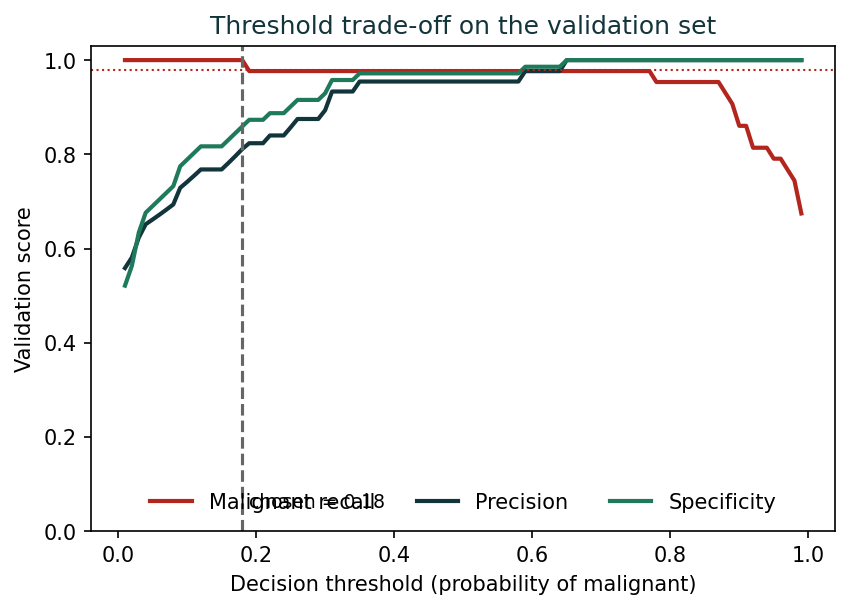

In [14]:
meta = json.loads(config.METADATA_PATH.read_text())
val = pd.read_csv(config.REPORTS_DIR / "validation_predictions.csv", index_col=0)
final_name, thr = meta["model_name"], meta["threshold"]
thr_chosen, table = evaluate.select_threshold(val["y_true"], val[final_name])
assert abs(thr_chosen - thr) < 1e-9
print(f"Final model: {final_name}; chosen threshold = {thr:.2f}")
for t in (0.5, thr):
    m = evaluate.compute_metrics(val["y_true"], val[final_name], t)
    print(f"  threshold {t:.2f}: recall={m['recall']:.3f} precision={m['precision']:.3f} FN={m['fn']} FP={m['fp']}")
display(Image(str(VIZ / "threshold_tradeoff.png")))

Lowering the threshold below 0.5 trades extra false alarms for fewer missed cancers. The
chosen value is the highest-precision threshold that still meets the recall target on validation.

## 9. Final evaluation on the untouched test set
We reload the saved pipeline, rebuild the *same* split (same seed) and score the test set. The
assertion confirms the notebook reproduces the numbers stored by `src/train.py`.

In [15]:
pipe = joblib.load(config.MODEL_PATH)
proba = pipe.predict_proba(s["X_test"])[:, 1]
tm = evaluate.compute_metrics(s["y_test"], proba, thr)
saved = json.loads((config.REPORTS_DIR / "metrics.json").read_text())
assert abs(tm["recall"] - saved["test"]["recall"]) < 1e-12 and abs(tm["roc_auc"] - saved["test"]["roc_auc"]) < 1e-12
ci = evaluate.bootstrap_ci(s["y_test"], proba, thr)
pd.DataFrame({"value": {k: tm[k] for k in ci}, "CI low": {k: v[0] for k, v in ci.items()},
              "CI high": {k: v[1] for k, v in ci.items()}}).round(3)

,value,CI low,CI high
accuracy,0.930,0.877,0.974
precision,0.854,0.733,0.948
recall,0.976,0.921,1.000
f1,0.911,0.833,0.966
roc_auc,0.995,0.984,1.000


{'tn': 65, 'fp': 7, 'fn': 1, 'tp': 41}


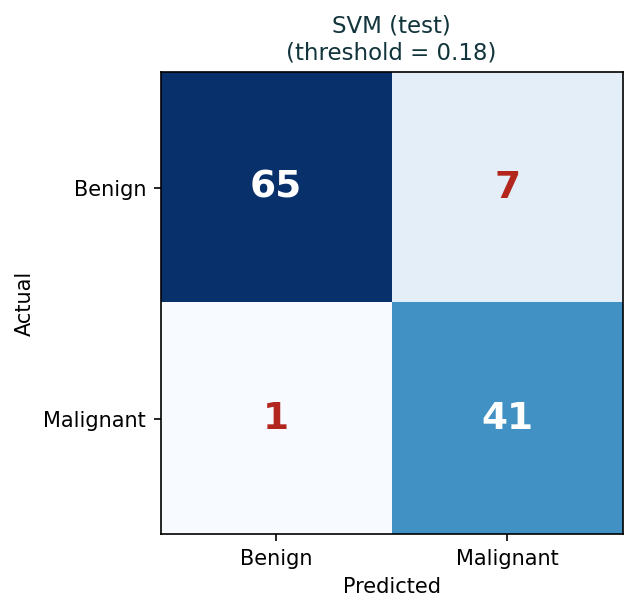

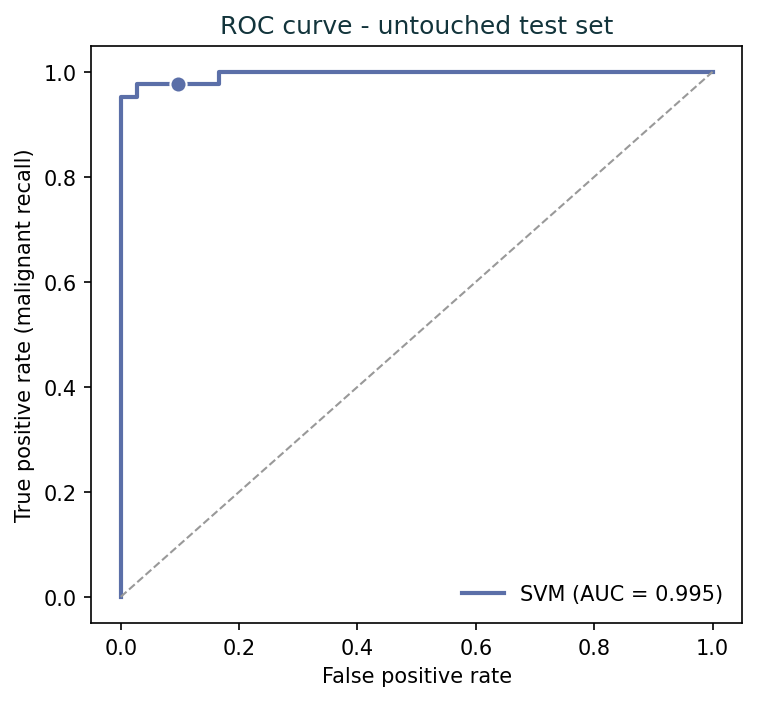

In [16]:
print({k: tm[k] for k in ("tn", "fp", "fn", "tp")})
display(Image(str(VIZ / "cm_test_final.png")))
display(Image(str(VIZ / "roc_test_final.png")))

The test set contains few malignant cases, so each miss moves recall by several points and
the bootstrap intervals are wide. These numbers are an honest estimate, not a guarantee.

## 10. False-negative analysis

In [17]:
imp = pd.read_csv(config.REPORTS_DIR / "feature_importance.csv")
fna = evaluate.false_negative_analysis(s["X_test"], s["y_test"], proba, thr, list(imp["feature"].head(5)))
print("Missed malignant cases (test):", len(fna["false_negatives"]))
print(fna["false_negatives"][["malignant_probability"]].round(3))
print("\nClosest calls among true malignant cases:")
print(fna["closest_calls"][["malignant_probability"]].round(3))
fna["profile"].round(3)

Missed malignant cases (test): 1
    malignant_probability
73                   0.07

Closest calls among true malignant cases:
     malignant_probability
73                   0.070
205                  0.447
190                  0.564
99                   0.594
39                   0.647


,feature,benign_median,malignant_median,false_negative_median
0,texture_worst,21.920,28.545,20.860
1,radius_se,0.256,0.536,0.279
2,concave_points_mean,0.024,0.081,0.051
3,symmetry_worst,0.261,0.306,0.259
4,concavity_worst,0.134,0.399,0.278


Compare the *missed-case median* with the benign and malignant medians: values nearer the
benign median mark an atypical malignant presentation. Borderline cases like these are why the
threshold is set below 0.5, but a case that scores far below the threshold cannot be rescued by
any reasonable cut-off.

## 11. Feature importance

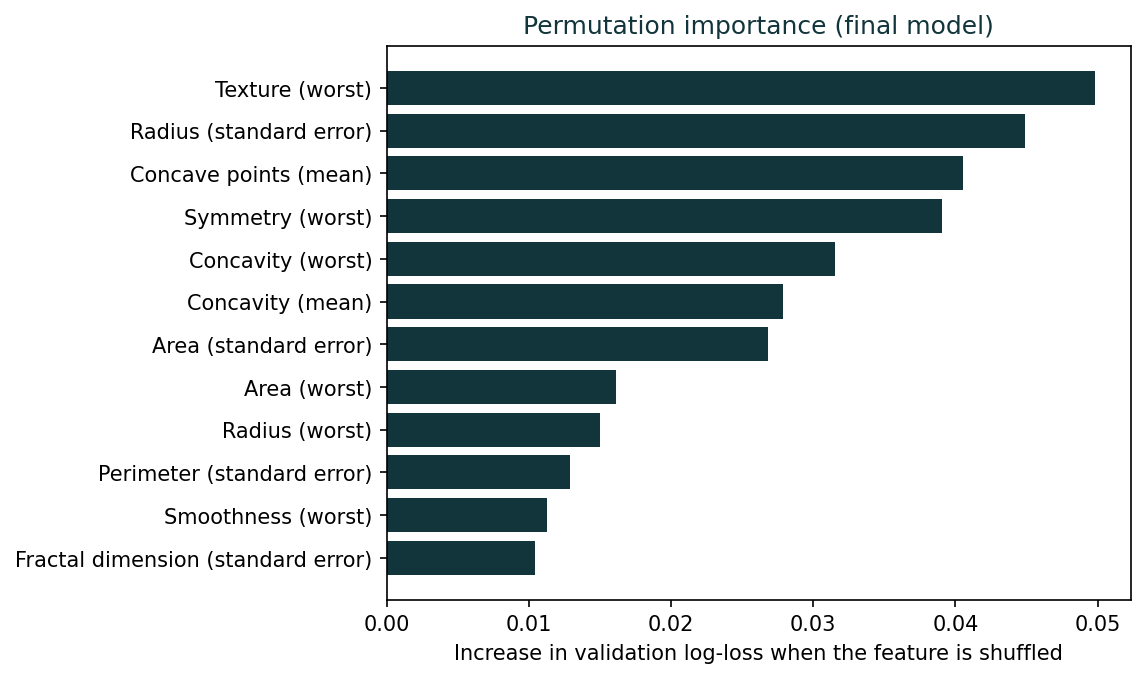

,feature,importance,std
0,texture_worst,0.0498,0.0206
1,radius_se,0.0449,0.0203
2,concave_points_mean,0.0405,0.0163
3,symmetry_worst,0.0390,0.0136
4,concavity_worst,0.0316,0.0118
5,concavity_mean,0.0279,0.0119
6,area_se,0.0268,0.0171
7,area_worst,0.0161,0.0084
8,radius_worst,0.0150,0.0079
9,perimeter_se,0.0129,0.0076


In [18]:
display(Image(str(VIZ / "permutation_importance.png")))
if meta.get("shap_available") and (VIZ / "shap_summary.png").exists():
    display(Image(str(VIZ / "shap_summary.png")))
imp.head(10).round(4)

Importance is measured on validation data. Because many features are correlated, importance is
shared among them and the ranking is approximate. These are associations, not medical causation.

## 12. Conclusions and limitations
- Strong separability on WDBC is expected and does **not** by itself indicate leakage; the pipeline
  design above rules it out.
- Small data (569 rows) means wide uncertainty; no external validation was performed.
- Educational project, **not a medical device**.